<a href="https://colab.research.google.com/github/Moises2206/Micro-proyecto-/blob/main/Proyecto_Final_Inmobiliario_Barranquilla.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🏠 Predicción del precio por m² de vivienda en Barranquilla
### Proyecto Final · Ciencia de Datos con Python

**Integrantes:**
- Integrante : moises de jesus barrios solano

---

**Problema.** Quien compra o vende vivienda en Barranquilla no tiene una referencia objetiva de cuánto *debería* valer el metro cuadrado de un inmueble según su ubicación y comodidades. Los precios publicados varían mucho entre barrios y tipos de inmueble.

**Objetivo.** Construir un flujo completo de Ciencia de Datos que:
1. **Extraiga automáticamente** anuncios reales de venta de apartamentos y casas del portal **Fincaraíz** (web scraping con bucles y URLs dinámicas), y la división de barrios por localidad desde **Wikipedia**.
2. **Limpie y transforme** la data cruda (concatenación, duplicados, nulos, casteo de tipos, filtros lógicos).
3. **Explore** visualmente los patrones del mercado.
4. **Prediga** el **precio por metro cuadrado (millones COP/m²)** con un modelo de regresión optimizado con **GridSearchCV + Validación Cruzada (5 folds)**.

**Variable objetivo:** `precio_m2` (millones de COP por m²).
**Variables independientes:** área, habitaciones, baños, administración, tipo de inmueble, localidad, estrato y comodidades (piscina, ascensor, gimnasio, parqueadero, vigilancia, balcón, aire acondicionado).

| Fase | Contenido |
|---|---|
| 0 | Configuración e importaciones |
| I | Web scraping automatizado (Fincaraíz + Wikipedia) |
| II | Manipulación y limpieza avanzada (Pandas & NumPy) |
| III | Análisis exploratorio y visualización |
| IV | Machine Learning: modelo base → GridSearchCV + CV 5 folds |
| V | Conclusiones |

## ⚙️ Fase 0 · Configuración del entorno
Importamos las librerías y definimos **en un solo lugar** los parámetros del proyecto (portal, ciudad, tipos de inmueble, número de páginas). Así, cambiar el alcance del scraping es cuestión de modificar una variable.

In [35]:
# ============================================================
# 0.1 Importaciones
# ============================================================
import re                      # expresiones regulares para extraer números del texto
import time                    # pausas entre peticiones (scraping responsable)
import random                  # pausas aleatorias para no saturar el servidor
import unicodedata             # normalizar tildes en nombres de barrios
import warnings
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import requests
from bs4 import BeautifulSoup

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, cross_val_score, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
print("✅ Librerías cargadas | pandas", pd.__version__)

✅ Librerías cargadas | pandas 2.2.3


In [36]:
# ============================================================
# 0.2 Parámetros del proyecto (variables dinámicas)
# ============================================================
BASE_URL      = "https://www.fincaraiz.com.co"
OPERACION     = "venta"
CIUDAD        = "barranquilla"
DEPARTAMENTO  = "atlantico"
TIPOS         = ["apartamentos", "casas"]   # categorías que recorrerá el bucle
PAGINAS_MAX   = 30                          # páginas por tipo (~21 anuncios por página)
PAUSA_SEG     = (1.0, 2.5)                  # pausa aleatoria entre peticiones
SEMILLA       = 42                          # reproducibilidad

URL_WIKI_BARRIOS = "https://es.wikipedia.org/wiki/Anexo:Barrios_de_Barranquilla"
LOCALIDADES      = ["Riomar", "Norte-Centro Histórico", "Metropolitana", "Suroccidente", "Suroriente"]

# Encabezados de navegador: el portal responde mejor a peticiones "humanas"
HEADERS = {
    "User-Agent": ("Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 "
                   "(KHTML, like Gecko) Chrome/124.0 Safari/537.36"),
    "Accept-Language": "es-CO,es;q=0.9",
    "Accept": "text/html,application/xhtml+xml,application/xml;q=0.9,*/*;q=0.8",
}

CARPETA_DATOS = Path("datos")
CARPETA_DATOS.mkdir(exist_ok=True)
ARCHIVO_RESPALDO = CARPETA_DATOS / "fincaraiz_crudo.csv"

np.random.seed(SEMILLA)
random.seed(SEMILLA)
print(f"Se recorrerán {len(TIPOS)} tipos × hasta {PAGINAS_MAX} páginas en {CIUDAD.title()}")

Se recorrerán 2 tipos × hasta 30 páginas en Barranquilla


## 🕸️ Fase I · Extracción de datos por Web Scraping automatizado

**Fuente principal:** [Fincaraíz](https://www.fincaraiz.com.co) — portal real de compra/venta de vivienda en Colombia.

La URL de cada página de resultados se **construye dinámicamente** combinando variables:

```
https://www.fincaraiz.com.co/{operacion}/{tipo}/{ciudad}/{departamento}/pagina{n}
```

**Lógica del scraping:**
1. Un bucle **`for`** recorre los **tipos de inmueble** (apartamentos, casas).
2. Dentro, un bucle **`while`** avanza **página por página** hasta `PAGINAS_MAX` o hasta que una página no traiga anuncios (fin de resultados).
3. Cada anuncio (tarjeta HTML) se convierte en un **diccionario** con sus campos *crudos en texto* (precio, m², habitaciones, baños, título, descripción).
4. Cada página se guarda como un **fragmento DataFrame** dentro del diccionario `fragmentos`, con clave `(tipo, página)`. Estos fragmentos se consolidan en la Fase II con `pd.concat()`.

> Nota técnica: Fincaraíz publica los anuncios como *tarjetas* (no como etiqueta `<table>`), por eso cada tarjeta se estructura en filas con BeautifulSoup y se convierte en tabla con **pandas**. La segunda fuente (Wikipedia) aporta la variable geográfica **localidad**.

In [37]:
# ============================================================
# 1.1 Funciones de apoyo para el scraping
# ============================================================
sesion = requests.Session()
sesion.headers.update(HEADERS)


def construir_url(tipo: str, pagina: int) -> str:
    # URL dinámica: la página 1 no lleva sufijo, las demás usan /paginaN
    url = f"{BASE_URL}/{OPERACION}/{tipo}/{CIUDAD}/{DEPARTAMENTO}"
    return url if pagina == 1 else f"{url}/pagina{pagina}"


def descargar_html(url: str, intentos: int = 3) -> str | None:
    # Descarga el HTML con reintentos; devuelve None si el servidor no responde 200
    for intento in range(1, intentos + 1):
        try:
            resp = sesion.get(url, timeout=25)
            if resp.status_code == 200:
                return resp.text
            print(f"   ⚠️ HTTP {resp.status_code} en intento {intento}")
        except requests.RequestException as err:
            print(f"   ⚠️ Error de conexión ({err.__class__.__name__}) en intento {intento}")
        time.sleep(2 * intento)   # espera progresiva antes de reintentar
    return None


# Patrón del enlace de cada anuncio: /apartamento-en-venta-en-<barrio>-<ciudad>/<id>
PATRON_ANUNCIO = re.compile(r"^/(apartamento|casa)[a-z\-]*-en-venta-en-[^/]+/(\d+)$")


def buscar(patron: str, texto: str) -> str | None:
    # Devuelve el primer grupo que coincida con el patrón o None
    m = re.search(patron, texto, flags=re.IGNORECASE)
    return m.group(1) if m else None


def parsear_tarjetas(html: str, tipo: str, pagina: int) -> list[dict]:
    # Convierte cada tarjeta de anuncio en un diccionario con campos CRUDOS (texto)
    soup = BeautifulSoup(html, "html.parser")
    registros = []
    for enlace in soup.find_all("a", href=PATRON_ANUNCIO):
        texto = enlace.get_text(" ", strip=True)
        if "$" not in texto:            # el enlace de la foto no trae texto: se omite
            continue
        h2 = enlace.find("h2")
        titulo = h2.get_text(" ", strip=True) if h2 else ""
        p_desc = h2.find_next_sibling("p") if h2 else None
        registros.append({
            "id_anuncio":   PATRON_ANUNCIO.match(enlace["href"]).group(2),
            "tipo_busqueda": tipo,
            "pagina":       pagina,
            "url":          BASE_URL + enlace["href"],
            "precio_txt":   buscar(r"(\$\s?[\d\.]+)", texto),
            "admin_txt":    buscar(r"\+\s?(\$\s?[\d\.]+)\s?admin", texto),
            "habs_txt":     buscar(r"(\d+\s?Habs?\.)", texto),
            "banos_txt":    buscar(r"(\d+\s?Baños?)", texto),
            "area_txt":     buscar(r"([\d\.,]+\s?m²)", texto),
            "titulo":       titulo,
            "descripcion":  p_desc.get_text(" ", strip=True) if p_desc else "",
            "fecha_extraccion": datetime.now().strftime("%Y-%m-%d"),
        })
    return registros

print("Ejemplo de URL dinámica:", construir_url(TIPOS[0], 3))

Ejemplo de URL dinámica: https://www.fincaraiz.com.co/venta/apartamentos/barranquilla/atlantico/pagina3


In [38]:
# ============================================================
# 1.2 Bucle principal de extracción (for + while)
# ============================================================
def extraer_anuncios() -> dict:
    fragmentos = {}                           # {(tipo, pagina): DataFrame}
    for tipo in TIPOS:                        # 🔁 bucle FOR sobre categorías
        print(f"\n🏷️  Tipo: {tipo.upper()}")
        pagina = 1
        while pagina <= PAGINAS_MAX:          # 🔁 bucle WHILE sobre páginas
            url = construir_url(tipo, pagina)
            html = descargar_html(url)
            if html is None:
                print(f"   ❌ Página {pagina} sin respuesta. Se detiene este tipo.")
                break
            registros = parsear_tarjetas(html, tipo, pagina)
            if not registros:                 # página vacía = fin de resultados
                print(f"   ⏹️ Página {pagina} sin anuncios. Fin del recorrido.")
                break
            fragmentos[(tipo, pagina)] = pd.DataFrame(registros)
            print(f"   ✔️ Página {pagina:>2}: {len(registros):>2} anuncios | {url}")
            pagina += 1
            time.sleep(random.uniform(*PAUSA_SEG))   # scraping responsable
    return fragmentos


inicio = time.time()
fragmentos = extraer_anuncios()
total = sum(len(f) for f in fragmentos.values())
print(f"\n📦 Fragmentos extraídos: {len(fragmentos)} | Registros crudos: {total} "
      f"| Tiempo: {time.time() - inicio:.0f} s")


🏷️  Tipo: APARTAMENTOS
   ✔️ Página  1: 17 anuncios | https://www.fincaraiz.com.co/venta/apartamentos/barranquilla/atlantico
   ✔️ Página  2: 19 anuncios | https://www.fincaraiz.com.co/venta/apartamentos/barranquilla/atlantico/pagina2
   ✔️ Página  3: 18 anuncios | https://www.fincaraiz.com.co/venta/apartamentos/barranquilla/atlantico/pagina3
   ✔️ Página  4: 17 anuncios | https://www.fincaraiz.com.co/venta/apartamentos/barranquilla/atlantico/pagina4
   ✔️ Página  5: 20 anuncios | https://www.fincaraiz.com.co/venta/apartamentos/barranquilla/atlantico/pagina5
   ✔️ Página  6: 19 anuncios | https://www.fincaraiz.com.co/venta/apartamentos/barranquilla/atlantico/pagina6
   ✔️ Página  7: 21 anuncios | https://www.fincaraiz.com.co/venta/apartamentos/barranquilla/atlantico/pagina7
   ✔️ Página  8: 21 anuncios | https://www.fincaraiz.com.co/venta/apartamentos/barranquilla/atlantico/pagina8
   ✔️ Página  9: 21 anuncios | https://www.fincaraiz.com.co/venta/apartamentos/barranquilla/atlantico/pa

In [39]:
# ============================================================
# 1.3 Respaldo de la extracción
# ============================================================
# Si la extracción fue exitosa se guarda una copia cruda con fecha.
# Si el portal bloquea temporalmente la IP de Colab, se usa la última copia
# generada POR ESTE MISMO SCRIPT (no es un dataset de Kaggle ni descargado).
if fragmentos:
    pd.concat(fragmentos.values(), ignore_index=True).to_csv(ARCHIVO_RESPALDO, index=False)
    print(f"💾 Respaldo crudo guardado en {ARCHIVO_RESPALDO}")
elif ARCHIVO_RESPALDO.exists():
    respaldo = pd.read_csv(ARCHIVO_RESPALDO, dtype=str)
    fragmentos = {(t, int(p)): g for (t, p), g in respaldo.groupby(["tipo_busqueda", "pagina"])}
    print(f"♻️ Portal no disponible: se cargan {len(respaldo)} registros del último scraping propio")
else:
    raise RuntimeError("No se pudo extraer información. Revisa la conexión y vuelve a ejecutar la Fase I.")

💾 Respaldo crudo guardado en datos/fincaraiz_crudo.csv


In [40]:
# Vista rápida de un fragmento crudo: TODO llega como texto
primer_fragmento = next(iter(fragmentos.values()))
primer_fragmento[["precio_txt", "admin_txt", "habs_txt", "banos_txt", "area_txt", "titulo"]].head()

,precio_txt,admin_txt,habs_txt,banos_txt,area_txt,titulo
0,$ 330.000.000,None,2 Habs.,2 Baños,64 m²,"Apartamento en venta en las delicias, barranqu..."
1,$ 390.000.000,$ 150.000,3 Habs.,2 Baños,110 m²,"Apartamento en venta en paraiso, barranquilla"
2,$ 720.000.000,None,3 Habs.,3 Baños,158 m²,"Apartamento en venta en villa santos, barranqu..."
3,$ 395.000.000,$ 408.400,3 Habs.,3 Baños,87 m²,"Apartamento en venta en ub. altos de parque, b..."
4,$ 250.000.000,None,2 Habs.,2 Baños,55 m²,"Apartamento en venta en la concepcion, barranq..."


### 1.4 Segunda fuente: localidades de Barranquilla (Wikipedia)
Para tener una **característica geográfica** robusta, recorremos con un bucle `for` las 5 localidades del anexo *Barrios de Barranquilla* y extraemos sus barrios. Si Wikipedia no responde, se usa un diccionario de respaldo con la misma información.

In [41]:
# ============================================================
# 1.4 Scraping de barrios por localidad
# ============================================================
def normalizar(texto: str) -> str:
    # minúsculas, sin tildes ni puntos: "Paraíso." -> "paraiso"
    texto = unicodedata.normalize("NFKD", str(texto)).encode("ascii", "ignore").decode()
    texto = re.sub(r"\(.*?\)", "", texto.lower())      # quita aclaraciones entre paréntesis
    texto = re.sub(r"[^a-z0-9 ]", " ", texto)          # puntos, comas y guiones -> espacio
    return " ".join(texto.split())


def extraer_barrios_wikipedia() -> dict:
    html = descargar_html(URL_WIKI_BARRIOS)
    if html is None:
        return {}
    soup = BeautifulSoup(html, "html.parser")
    mapa = {}
    for localidad in LOCALIDADES:                         # 🔁 bucle FOR sobre regiones
        h2 = next((h for h in soup.find_all("h2") if h.get_text(strip=True) == localidad), None)
        lista = h2.find_next("ul") if h2 else None
        if lista is None:
            continue
        for li in lista.find_all("li"):
            barrio = normalizar(li.get_text(" ", strip=True).replace("Centro poblado", ""))
            if barrio:
                mapa.setdefault(barrio, localidad)        # primera localidad encontrada
    return mapa


# Respaldo (misma información del anexo de Wikipedia, barrios con oferta frecuente)
MAPA_RESPALDO = {
    "Riomar": ["adela de char", "altamira", "altos de riomar", "altos del limon", "altos del prado",
               "alto prado", "andalucia", "buenavista", "el castillo i", "el limoncito", "el poblado",
               "la castellana", "la floresta", "las flores", "las tres avemarias", "paraiso", "riomar",
               "san marino", "san salvador", "san vicente", "santa monica", "siape", "solaire",
               "villa campestre", "villa carolina", "villa del este", "villa santos", "villamar",
               "villas del puerto", "la playa", "miramar"],
    "Norte-Centro Histórico": ["alameda del rio", "america", "barlovento", "barranquillita", "barrio abajo",
               "bellavista", "betania", "boston", "campo alegre", "centro", "ciudad jardin", "colombia",
               "el boliche", "el castillo", "el golf", "el porvenir", "el prado", "el recreo", "el rosario",
               "el tabor", "granadillo", "la campina", "la concepcion", "la cumbre", "la felicidad", "la loma",
               "las colinas", "las delicias", "las mercedes", "los alpes", "los jobos", "los nogales",
               "modelo", "montecristo", "nuevo horizonte", "parque rosado", "san francisco", "santa ana",
               "villa country", "villa tarel", "villanueva", "prado"],
    "Metropolitana": ["7 de abril", "20 de julio", "buenos aires", "carrizal", "ciudadela 20 de julio",
               "el santuario", "kennedy", "la sierrita", "las americas", "las cayenas", "las gardenias",
               "las granjas", "los continentes", "los girasoles", "san luis", "santa maria",
               "santo domingo de guzman", "villa san carlos", "villa san pedro", "villa sevilla"],
    "Suroccidente": ["7 de agosto", "buena esperanza", "california", "caribe verde", "carlos meisel",
               "cevillar", "ciudad modesto", "colina campestre", "cordialidad", "el bosque", "el carmen",
               "el eden 2000", "el golfo", "el pueblo", "el romance", "el rubi", "el silencio", "el valle",
               "evaristo sourdis", "kalamary", "la ceiba", "la esmeralda", "la florida", "la gloria",
               "la libertad", "la manga", "la paz", "la pradera", "la sierra", "las estrellas", "las malvinas",
               "las terrazas", "lipaya", "loma fresca", "los andes", "los olivos", "los pinos", "los rosales",
               "lucero", "mequejo", "nueva granada", "olaya", "san felipe", "san isidro", "villate",
               "villa flor", "pinar del rio", "villas de san pablo", "juan mina"],
    "Suroriente": ["alfonso lopez", "atlantico", "bella arena", "boyaca", "chiquinquira", "el campito",
               "el ferry", "el limon", "el milagro", "jose antonio galan", "la alboraya", "la chinita",
               "la luz", "la magdalena", "la union", "la victoria", "las dunas", "las nieves", "las palmas",
               "las palmeras", "los laureles", "los trupillos", "moderno", "montes", "pasadena",
               "primero de mayo", "rebolo", "san jose", "san nicolas", "san roque", "santa elena",
               "simon bolivar", "tayrona", "universal", "villa blanca", "villa del carmen", "zona franca"],
}

mapa_barrios = extraer_barrios_wikipedia()
fuente = "Wikipedia"
if len(mapa_barrios) < 50:
    mapa_barrios, fuente = {}, "respaldo interno"
for loc, barrios in MAPA_RESPALDO.items():   # complementa alias comunes en los anuncios
    for b in barrios:
        mapa_barrios.setdefault(b, loc)

df_localidades = (pd.DataFrame(list(mapa_barrios.items()), columns=["barrio_norm", "localidad"]))
print(f"🗺️ {len(df_localidades)} barrios mapeados a localidad (fuente: {fuente})")
df_localidades["localidad"].value_counts()

🗺️ 190 barrios mapeados a localidad (fuente: Wikipedia)


,count
localidad,
Suroccidente,54
Norte-Centro Histórico,44
Suroriente,35
Riomar,31
Metropolitana,26


## 🧹 Fase II · Manipulación y limpieza avanzada (Pandas & NumPy)
Pasos:
1. **Concatenación** de todos los fragmentos con `pd.concat()`.
2. **Duplicados**: el portal repite anuncios *destacados* en varias páginas y algunas inmobiliarias publican el mismo inmueble.
3. **Casteo de tipos**: texto (`"$ 330.000.000"`, `"64 m²"`, `"2 Habs."`) → números.
4. **Ingeniería de variables** desde el texto: barrio, localidad, estrato y comodidades.
5. **Valores faltantes (NaN)**: tratamiento justificado columna por columna.
6. **Filtrado avanzado** con condiciones múltiples anidadas (`&`, `|`, `~`) bien agrupadas con paréntesis.

In [42]:
# ============================================================
# 2.1 Concatenación eficiente de fragmentos
# ============================================================
df_crudo = pd.concat(fragmentos.values(), ignore_index=True)
print(f"Forma del dataset crudo: {df_crudo.shape}")
df_crudo.info()

Forma del dataset crudo: (1241, 12)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1241 entries, 0 to 1240
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   id_anuncio        1241 non-null   object
 1   tipo_busqueda     1241 non-null   object
 2   pagina            1241 non-null   int64 
 3   url               1241 non-null   object
 4   precio_txt        1241 non-null   object
 5   admin_txt         638 non-null    object
 6   habs_txt          1210 non-null   object
 7   banos_txt         1234 non-null   object
 8   area_txt          1241 non-null   object
 9   titulo            1241 non-null   object
 10  descripcion       1241 non-null   object
 11  fecha_extraccion  1241 non-null   object
dtypes: int64(1), object(11)
memory usage: 116.5+ KB


In [43]:
# ============================================================
# 2.2 Identificación y tratamiento de duplicados
# ============================================================
n0 = len(df_crudo)
dup_id = df_crudo.duplicated(subset="id_anuncio").sum()
df = df_crudo.drop_duplicates(subset="id_anuncio", keep="first").copy()

# Mismo inmueble publicado por distintas inmobiliarias: igual precio, área, habs, baños y título
claves = ["precio_txt", "area_txt", "habs_txt", "banos_txt", "titulo"]
dup_contenido = df.duplicated(subset=claves).sum()
df = df.drop_duplicates(subset=claves, keep="first")

print(f"Registros crudos:                    {n0}")
print(f"Duplicados por id (destacados):      {dup_id}")
print(f"Duplicados por contenido idéntico:   {dup_contenido}")
print(f"Registros únicos:                    {len(df)}")

Registros crudos:                    1241
Duplicados por id (destacados):      0
Duplicados por contenido idéntico:   24
Registros únicos:                    1217


In [44]:
# ============================================================
# 2.3 Conversión y casteo explícito de texto a numérico
# ============================================================
def texto_a_numero(serie: pd.Series) -> pd.Series:
    # "$ 1.270.000.000" -> 1270000000.0 | "64 m²" -> 64.0 | "2 Habs." -> 2.0
    limpio = (serie.astype("string")
                   .str.replace(r"[^\d,]", "", regex=True)   # deja solo dígitos y coma decimal
                   .str.replace(",", ".", regex=False))
    return pd.to_numeric(limpio, errors="coerce")             # lo no convertible -> NaN

df["precio"]       = texto_a_numero(df["precio_txt"]).astype("float64")
df["admin"]        = texto_a_numero(df["admin_txt"]).astype("float64")
df["area_m2"]      = texto_a_numero(df["area_txt"]).astype("float64")
df["habitaciones"] = texto_a_numero(df["habs_txt"]).astype("Int64")
df["banos"]        = texto_a_numero(df["banos_txt"]).astype("Int64")
df["tipo"]         = df["tipo_busqueda"].map({"apartamentos": "Apartamento", "casas": "Casa"}).astype("category")

print("Antes:", df[["precio_txt", "area_txt", "habs_txt"]].dtypes.tolist())
print("Después:", df[["precio", "area_m2", "habitaciones"]].dtypes.tolist())
df[["precio_txt", "precio", "area_txt", "area_m2", "habs_txt", "habitaciones"]].head()

Antes: [dtype('O'), dtype('O'), dtype('O')]
Después: [dtype('float64'), dtype('float64'), Int64Dtype()]


,precio_txt,precio,area_txt,area_m2,habs_txt,habitaciones
0,$ 330.000.000,"330,000,000.00",64 m²,64.00,2 Habs.,2
1,$ 390.000.000,"390,000,000.00",110 m²,110.00,3 Habs.,3
2,$ 720.000.000,"720,000,000.00",158 m²,158.00,3 Habs.,3
3,$ 395.000.000,"395,000,000.00",87 m²,87.00,3 Habs.,3
4,$ 250.000.000,"250,000,000.00",55 m²,55.00,2 Habs.,2


In [45]:
# ============================================================
# 2.4 Ingeniería de variables desde el texto del anuncio
# ============================================================
# Barrio: "Apartamento en venta en villa santos, barranquilla" -> "villa santos"
df["barrio"] = (df["titulo"].str.extract(r"en venta en (.+?)(?:,|$)", flags=re.IGNORECASE)[0]
                  .fillna("").map(normalizar))
df["barrio"] = df["barrio"].str.replace(r"^(cr|urb|conj|br)\s+", "", regex=True)  # "cr.la castellana"

def asignar_localidad(barrio: str) -> str:
    if barrio in mapa_barrios:                         # coincidencia exacta
        return mapa_barrios[barrio]
    for nombre in sorted(mapa_barrios, key=len, reverse=True):   # coincidencia parcial
        if len(nombre) > 4 and nombre in barrio:
            return mapa_barrios[nombre]
    return "Sin clasificar"

df["localidad"] = df["barrio"].map(asignar_localidad)

# Texto completo en minúsculas para buscar comodidades
texto = (df["titulo"].fillna("") + " " + df["descripcion"].fillna("")).str.lower()
df["estrato"] = pd.to_numeric(texto.str.extract(r"estrato\s*:?\s*([1-6])")[0], errors="coerce")

COMODIDADES = {
    "piscina":      r"piscina",
    "ascensor":     r"ascensor",
    "gimnasio":     r"gimnasio|gym",
    "parqueadero":  r"parqueadero|garaje",
    "vigilancia":   r"vigilancia|porter[ií]a|seguridad 24",
    "balcon":       r"balc[oó]n",
    "aire_acond":   r"aire acondicionado|aires acondicionados",
}
for nombre, patron in COMODIDADES.items():
    df[nombre] = texto.str.contains(patron, regex=True).astype(int)

df["n_comodidades"] = df[list(COMODIDADES)].sum(axis=1)
df[["barrio", "localidad", "estrato", *COMODIDADES]].head()

,barrio,localidad,estrato,piscina,ascensor,gimnasio,parqueadero,vigilancia,balcon,aire_acond
0,las delicias,Norte-Centro Histórico,NaN,1,1,0,1,1,1,0
1,paraiso,Riomar,NaN,0,1,0,1,0,0,0
2,villa santos,Riomar,NaN,1,0,1,1,1,1,0
3,ub altos de parque,Sin clasificar,4.00,1,1,0,1,1,1,0
4,la concepcion,Norte-Centro Histórico,NaN,1,1,1,1,1,0,0


In [46]:
# ============================================================
# 2.5 Diagnóstico de valores faltantes (NaN)
# ============================================================
columnas_clave = ["precio", "area_m2", "habitaciones", "banos", "admin", "estrato"]
nulos = pd.DataFrame({
    "nulos": df[columnas_clave].isna().sum(),
    "porcentaje": (df[columnas_clave].isna().mean() * 100).round(1),
})
nulos

,nulos,porcentaje
precio,0,0.00
area_m2,0,0.00
habitaciones,31,2.50
banos,7,0.60
admin,594,48.80
estrato,968,79.50


**Decisiones sobre los NaN (justificadas):**

| Columna | Tratamiento | Justificación |
|---|---|---|
| `precio`, `area_m2` | **Eliminar fila** | Son la base de la variable objetivo: imputarlas inventaría el precio/m². |
| `habitaciones`, `banos` | **Mediana por tipo** de inmueble | Pocos casos; una casa y un apartamento tienen distribuciones distintas. |
| `admin` | **0 + indicador** `tiene_admin` | Si no se publica administración, generalmente el inmueble no está en conjunto (casas). |
| `estrato` | **Mediana del barrio**, luego de la localidad | El estrato es una característica del sector; los vecinos del mismo barrio comparten estrato. Lo que siga faltando se imputa dentro del *pipeline* del modelo (sin fuga de datos). |

In [47]:
# ============================================================
# 2.6 Tratamiento explícito de NaN
# ============================================================
antes = len(df)
df = df.dropna(subset=["precio", "area_m2"]).copy()
print(f"Filas eliminadas sin precio o área: {antes - len(df)}")

for col in ["habitaciones", "banos"]:
    df[col] = df[col].fillna(df.groupby("tipo", observed=True)[col].transform("median").round()).astype("Int64")

df["tiene_admin"] = df["admin"].notna().astype(int)
df["admin"] = df["admin"].fillna(0)

df["estrato"] = df["estrato"].fillna(df.groupby("barrio")["estrato"].transform("median"))
df["estrato"] = df["estrato"].fillna(df.groupby("localidad")["estrato"].transform("median")).round()

# Variable objetivo: millones de COP por metro cuadrado
df["precio_m2"] = df["precio"] / df["area_m2"] / 1e6
df["admin_m2"] = df["admin"] / df["area_m2"]           # admin por m² (COP)

print("NaN restantes:\n", df[columnas_clave].isna().sum())

Filas eliminadas sin precio o área: 0
NaN restantes:
 precio           0
area_m2          0
habitaciones     0
banos            0
admin            0
estrato         19
dtype: int64


In [48]:
# ============================================================
# 2.7 Filtrado avanzado con condiciones múltiples anidadas
# ============================================================
# Se excluyen errores de digitación y valores fuera de mercado.
# Paréntesis explícitos: Python evalúa & antes que |, por eso se agrupa cada bloque.
q_bajo, q_alto = df["precio_m2"].quantile([0.01, 0.99])

filtro = (
    (
        ((df["tipo"] == "Apartamento") & (df["area_m2"].between(25, 600)) & (df["habitaciones"] <= 6))
        |
        ((df["tipo"] == "Casa") & (df["area_m2"].between(40, 1500)) & (df["habitaciones"] <= 12))
    )
    & (df["precio"].between(60e6, 20e9))                          # precios de venta realistas
    & (df["precio_m2"].between(q_bajo, q_alto))                   # recorta el 1% extremo
    & ~(
        (df["banos"] > df["habitaciones"] + 4)                       # más baños que lógica
        | ((df["habitaciones"] == 0) & (df["area_m2"] > 150))        # lote/bodega mal clasificado
    )
)
filtro = filtro.fillna(False).astype(bool)   # comparaciones con NA cuentan como no cumplen

df_limpio = df.loc[filtro].reset_index(drop=True)
print(f"Registros antes del filtro: {len(df)} | después: {len(df_limpio)} "
      f"| descartados: {len(df) - len(df_limpio)}")
print(f"Rango de precio/m² conservado: {q_bajo:.2f} – {q_alto:.2f} millones COP")

Registros antes del filtro: 1217 | después: 1183 | descartados: 34
Rango de precio/m² conservado: 1.38 – 11.01 millones COP


In [49]:
# Resumen estadístico del dataset limpio
cols_resumen = ["precio", "area_m2", "precio_m2", "habitaciones", "banos", "estrato", "admin"]
df_limpio[cols_resumen].describe().T

,count,mean,std,min,25%,50%,75%,max
precio,"1,183.00","839,473,749.98","757,049,671.65","80,000,000.00","380,000,000.00","600,000,000.00","992,500,000.00","8,000,000,000.00"
area_m2,"1,183.00",203.74,168.56,37.00,90.00,149.00,260.00,"1,357.00"
precio_m2,"1,183.00",4.39,1.66,1.39,3.16,4.17,5.33,11.00
habitaciones,"1,183.00",3.43,1.33,2.00,3.00,3.00,4.00,11.00
banos,"1,183.00",3.04,1.39,1.00,2.00,3.00,4.00,10.00
estrato,"1,168.00",4.40,0.98,2.00,4.00,4.00,5.00,6.00
admin,"1,183.00","2,458,123.15","46,013,314.70",0.00,0.00,"150,000.00","590,000.00","1,130,000,000.00"


In [50]:
# Guardar el dataset limpio para trazabilidad
df_limpio.to_csv(CARPETA_DATOS / "fincaraiz_limpio.csv", index=False)
print("💾 Dataset limpio guardado:", CARPETA_DATOS / "fincaraiz_limpio.csv", df_limpio.shape)

💾 Dataset limpio guardado: datos/fincaraiz_limpio.csv (1183, 32)


## 📊 Fase III · Análisis exploratorio y visualización
Buscamos responder: **¿qué explica el precio por m²?** Revisamos la distribución de la variable objetivo y su relación con la ubicación, el tamaño, el estrato y las comodidades. Debajo de cada gráfico, una celda imprime la **interpretación calculada con los datos**, para que las conclusiones siempre coincidan con lo extraído el día de la ejecución.

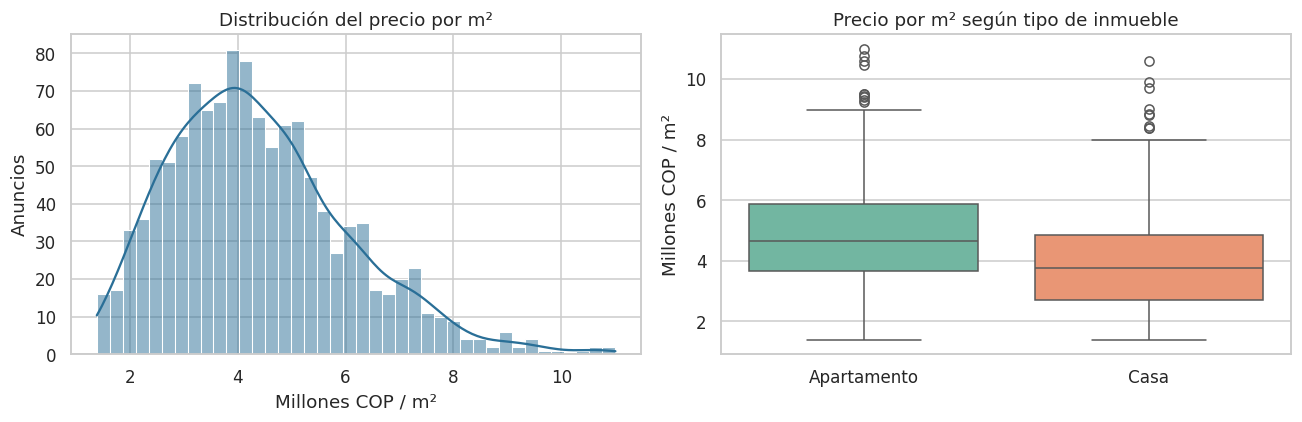

📝 Mediana general: 4.17 M/m² | asimetría: 0.76 (>0 = cola hacia precios altos)
📝 Mediana por tipo: Apartamento: 4.65 M/m², Casa: 3.76 M/m²


In [51]:
# 3.1 Distribución de la variable objetivo
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df_limpio["precio_m2"], bins=40, kde=True, ax=ax[0], color="#2a6f97")
ax[0].set(title="Distribución del precio por m²", xlabel="Millones COP / m²", ylabel="Anuncios")
sns.boxplot(data=df_limpio, x="tipo", y="precio_m2", ax=ax[1], palette="Set2")
ax[1].set(title="Precio por m² según tipo de inmueble", xlabel="", ylabel="Millones COP / m²")
plt.tight_layout(); plt.show()

med = df_limpio.groupby("tipo", observed=True)["precio_m2"].median()
print(f"📝 Mediana general: {df_limpio['precio_m2'].median():.2f} M/m² | "
      f"asimetría: {df_limpio['precio_m2'].skew():.2f} (>0 = cola hacia precios altos)")
print("📝 Mediana por tipo:", ", ".join(f"{k}: {v:.2f} M/m²" for k, v in med.items()))

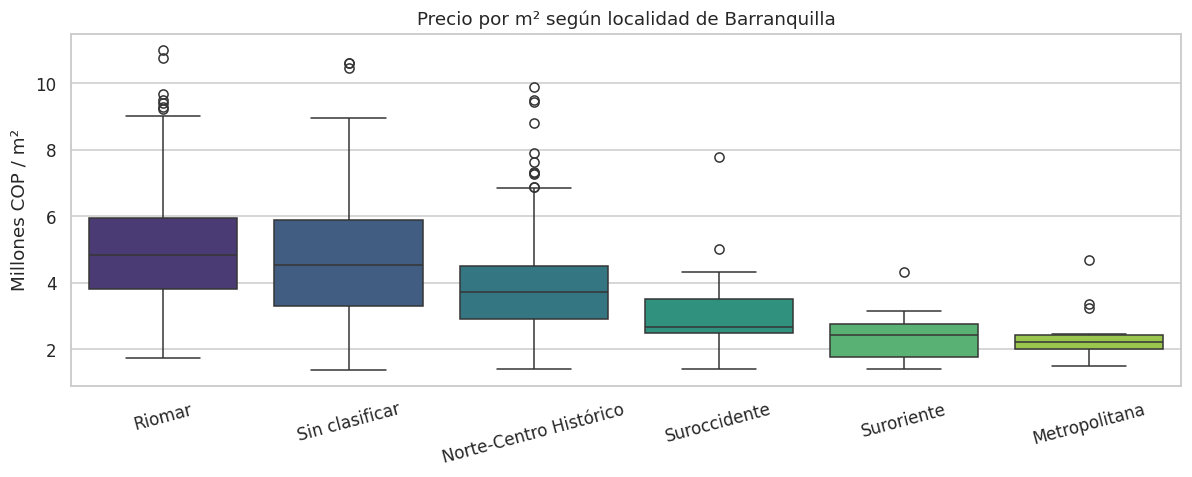

,anuncios,mediana
localidad,,
Riomar,520,4.83
Sin clasificar,209,4.54
Norte-Centro Histórico,376,3.74
Suroccidente,49,2.67
Suroriente,15,2.44
Metropolitana,14,2.23


📝 Riomar es la localidad más costosa (4.83 M/m²), 2.2 veces Metropolitana.


In [52]:
# 3.2 Ubicación: precio por m² según localidad
orden = df_limpio.groupby("localidad")["precio_m2"].median().sort_values(ascending=False).index
plt.figure(figsize=(11, 4.5))
sns.boxplot(data=df_limpio, x="localidad", y="precio_m2", order=orden, palette="viridis")
plt.title("Precio por m² según localidad de Barranquilla")
plt.xlabel(""); plt.ylabel("Millones COP / m²"); plt.xticks(rotation=15)
plt.tight_layout(); plt.show()

resumen_loc = (df_limpio.groupby("localidad")["precio_m2"]
               .agg(anuncios="count", mediana="median").sort_values("mediana", ascending=False))
display(resumen_loc)
top, fondo = resumen_loc.index[0], resumen_loc.index[-1]
print(f"📝 {top} es la localidad más costosa ({resumen_loc.loc[top,'mediana']:.2f} M/m²), "
      f"{resumen_loc.loc[top,'mediana']/resumen_loc.loc[fondo,'mediana']:.1f} veces {fondo}.")

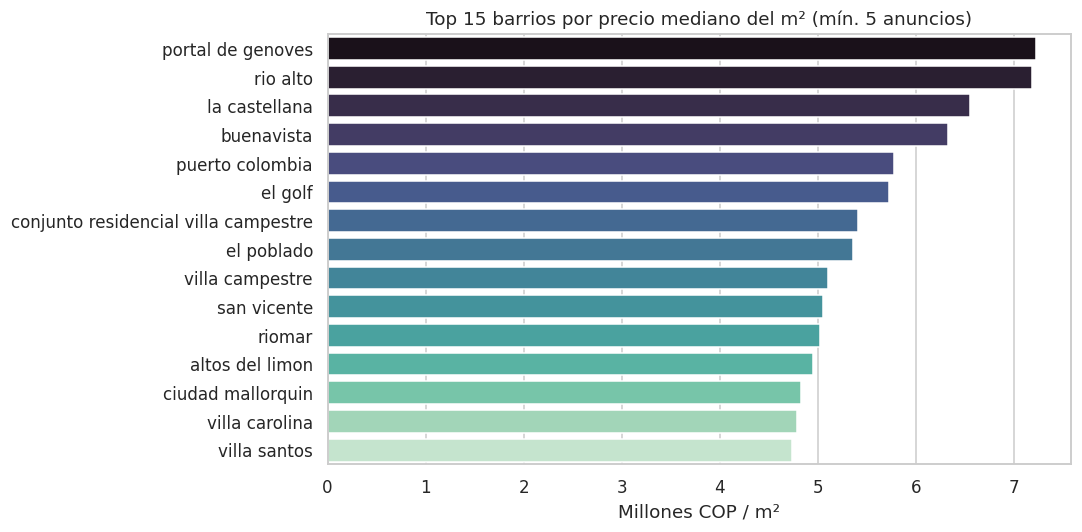

📝 Barrio más costoso: Portal De Genoves (7.22 M/m²).


In [53]:
# 3.3 Top barrios con al menos 5 anuncios
top_barrios = (df_limpio.groupby("barrio").filter(lambda g: len(g) >= 5)
               .groupby("barrio")["precio_m2"].median().sort_values(ascending=False).head(15))
plt.figure(figsize=(10, 5))
sns.barplot(x=top_barrios.values, y=top_barrios.index, palette="mako")
plt.title("Top 15 barrios por precio mediano del m² (mín. 5 anuncios)")
plt.xlabel("Millones COP / m²"); plt.ylabel("")
plt.tight_layout(); plt.show()
print(f"📝 Barrio más costoso: {top_barrios.index[0].title()} ({top_barrios.iloc[0]:.2f} M/m²).")

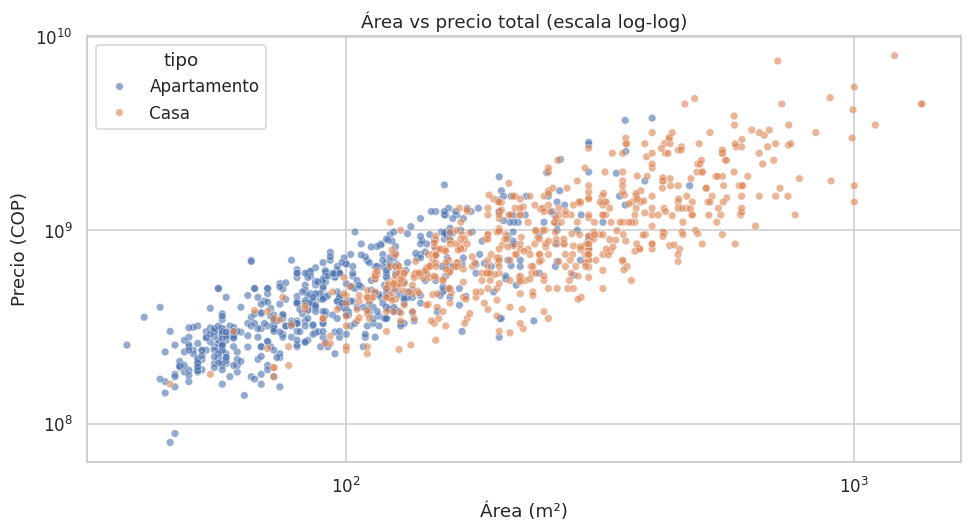

📝 El precio total sube con el área, pero la correlación área–precio/m² es -0.26: los inmuebles grandes tienden a costar menos por m².


In [54]:
# 3.4 Tamaño vs precio (escala logarítmica)
plt.figure(figsize=(9, 5))
sns.scatterplot(data=df_limpio, x="area_m2", y="precio", hue="tipo", alpha=0.6, s=25)
plt.xscale("log"); plt.yscale("log")
plt.title("Área vs precio total (escala log-log)")
plt.xlabel("Área (m²)"); plt.ylabel("Precio (COP)")
plt.tight_layout(); plt.show()

corr_area = df_limpio[["area_m2", "precio_m2"]].corr(method="spearman").iloc[0, 1]
print(f"📝 El precio total sube con el área, pero la correlación área–precio/m² es {corr_area:.2f}: "
      f"{'los inmuebles grandes tienden a costar menos por m²' if corr_area < 0 else 'el m² se encarece en inmuebles más grandes'}.")

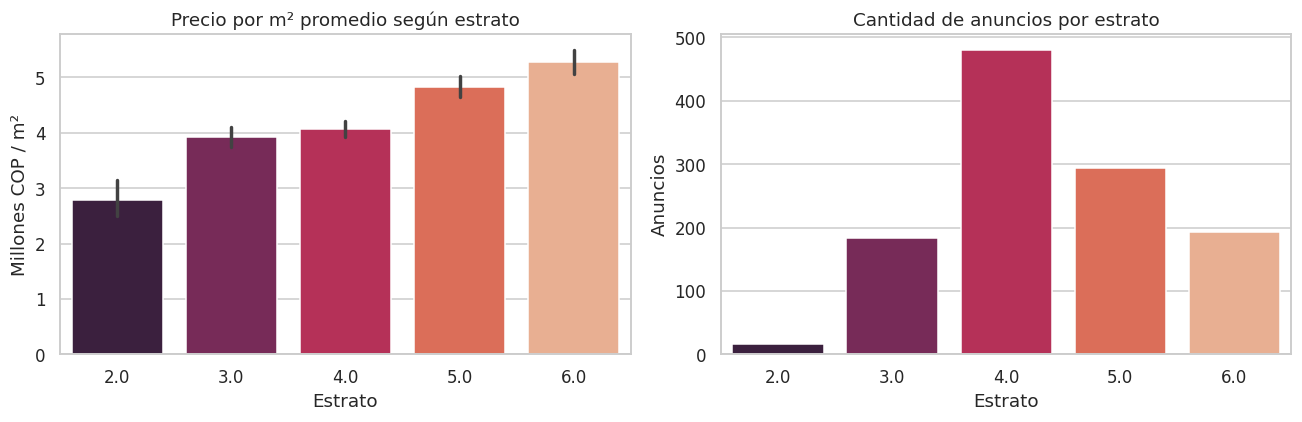

📝 Precio/m² medio por estrato: {2.0: 2.79, 3.0: 3.92, 4.0: 4.07, 5.0: 4.82, 6.0: 5.27}


In [55]:
# 3.5 Estrato y precio por m²
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(data=df_limpio, x="estrato", y="precio_m2", ax=ax[0], palette="rocket", errorbar=("ci", 95))
ax[0].set(title="Precio por m² promedio según estrato", xlabel="Estrato", ylabel="Millones COP / m²")
sns.countplot(data=df_limpio, x="estrato", ax=ax[1], palette="rocket")
ax[1].set(title="Cantidad de anuncios por estrato", xlabel="Estrato", ylabel="Anuncios")
plt.tight_layout(); plt.show()
print("📝 Precio/m² medio por estrato:",
      df_limpio.groupby("estrato")["precio_m2"].mean().round(2).to_dict())

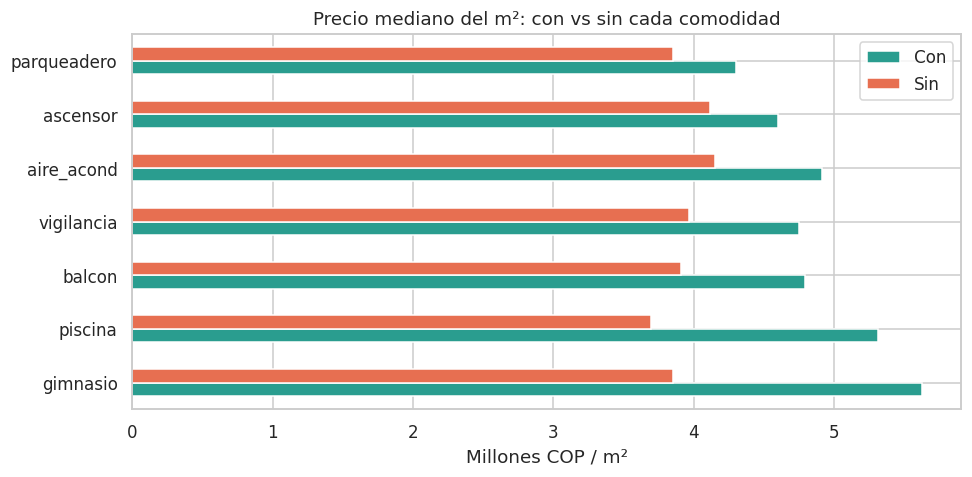

,Con,Sin,diferencia_%
gimnasio,5.62,3.85,45.92
piscina,5.31,3.69,43.84
balcon,4.79,3.91,22.61
vigilancia,4.75,3.96,19.85
aire_acond,4.91,4.15,18.35
ascensor,4.60,4.12,11.74
parqueadero,4.30,3.85,11.53


📝 La comodidad asociada a mayor prima es 'gimnasio' (+46% en el m² mediano).


In [56]:
# 3.6 Efecto de las comodidades
efecto = pd.DataFrame({
    c: {"Con": df_limpio.loc[df_limpio[c] == 1, "precio_m2"].median(),
        "Sin": df_limpio.loc[df_limpio[c] == 0, "precio_m2"].median()}
    for c in COMODIDADES}).T
efecto["diferencia_%"] = (efecto["Con"] / efecto["Sin"] - 1) * 100
efecto = efecto.sort_values("diferencia_%", ascending=False)

efecto[["Con", "Sin"]].plot(kind="barh", figsize=(9, 4.5), color=["#2a9d8f", "#e76f51"])
plt.title("Precio mediano del m²: con vs sin cada comodidad")
plt.xlabel("Millones COP / m²"); plt.tight_layout(); plt.show()
display(efecto.round(2))
print(f"📝 La comodidad asociada a mayor prima es '{efecto.index[0]}' (+{efecto['diferencia_%'].iloc[0]:.0f}% en el m² mediano).")

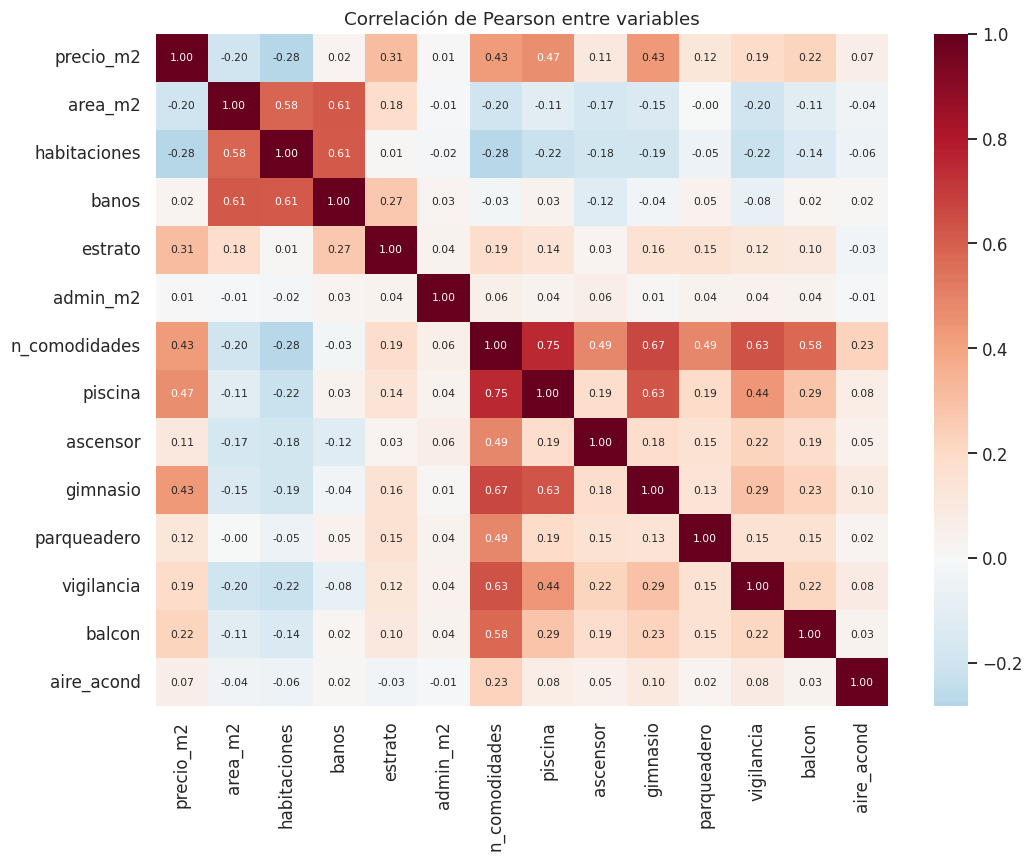

📝 Variables más correlacionadas con el precio/m²: {'piscina': 0.47, 'gimnasio': 0.43, 'n_comodidades': 0.43, 'estrato': 0.31}


In [57]:
# 3.7 Matriz de correlación de variables numéricas
num_cols = ["precio_m2", "area_m2", "habitaciones", "banos", "estrato", "admin_m2", "n_comodidades", *COMODIDADES]
plt.figure(figsize=(10, 8))
sns.heatmap(df_limpio[num_cols].astype(float).corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            annot_kws={"size": 7})
plt.title("Correlación de Pearson entre variables")
plt.tight_layout(); plt.show()
corr_obj = df_limpio[num_cols].astype(float).corr()["precio_m2"].drop("precio_m2").sort_values(key=abs, ascending=False)
print("📝 Variables más correlacionadas con el precio/m²:", corr_obj.head(4).round(2).to_dict())

## 🤖 Fase IV · Machine Learning avanzado y optimización
**Tipo de problema:** regresión (predecir `precio_m2`).

**Metodología (sin fuga de datos):**
1. División **train/test 80/20** antes de cualquier ajuste.
2. Todo el preprocesamiento (imputación, escalado, *one-hot*) vive dentro de un **`Pipeline`**, así cada fold de la validación cruzada aprende el preprocesamiento **solo** con sus datos de entrenamiento.
3. **Modelo base:** Support Vector Regression (SVR) con hiperparámetros por defecto → score con **CV de 5 folds**.
4. **Optimización:** **GridSearchCV** exhaustivo sobre `C`, `epsilon`, `gamma` y `kernel` con la misma CV de 5 folds.
5. Comparación adicional con **Random Forest** (también optimizado) y elección del mejor.
6. Evaluación final en el **test** (datos nunca vistos) y documentación del incremento del score.

In [58]:
# ============================================================
# 4.1 Selección de variables y división train/test
# ============================================================
VARS_NUM = ["area_m2", "habitaciones", "banos", "estrato", "admin_m2"]
VARS_CAT = ["tipo", "localidad"]
VARS_BIN = [*COMODIDADES, "tiene_admin"]
OBJETIVO = "precio_m2"

X = df_limpio[VARS_NUM + VARS_CAT + VARS_BIN].copy()
X[VARS_NUM] = X[VARS_NUM].astype(float)
X[VARS_CAT] = X[VARS_CAT].astype(str)
y = df_limpio[OBJETIVO].astype(float)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=SEMILLA)
print(f"Train: {X_train.shape} | Test: {X_test.shape}")

Train: (946, 15) | Test: (237, 15)


In [59]:
# ============================================================
# 4.2 Preprocesamiento dentro de un Pipeline
# ============================================================
preprocesador = ColumnTransformer([
    ("num", Pipeline([("imputar", SimpleImputer(strategy="median")),
                      ("escalar", StandardScaler())]), VARS_NUM),
    ("cat", Pipeline([("imputar", SimpleImputer(strategy="most_frequent")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore"))]), VARS_CAT),
    ("bin", "passthrough", VARS_BIN),
])

cv = KFold(n_splits=5, shuffle=True, random_state=SEMILLA)   # validación cruzada de 5 folds


def evaluar_en_test(modelo, nombre):
    pred = modelo.predict(X_test)
    return {"modelo": nombre,
            "R2_test": r2_score(y_test, pred),
            "MAE_test (M/m²)": mean_absolute_error(y_test, pred),
            "RMSE_test (M/m²)": np.sqrt(mean_squared_error(y_test, pred))}

In [60]:
# ============================================================
# 4.3 Modelo BASE: SVR con hiperparámetros por defecto
# ============================================================
svr_base = Pipeline([("prep", preprocesador), ("svr", SVR())])

cv_base = cross_val_score(svr_base, X_train, y_train, cv=cv, scoring="r2")
svr_base.fit(X_train, y_train)
res_base = evaluar_en_test(svr_base, "SVR base")

print("R² por fold:", np.round(cv_base, 3))
print(f"📌 SVR base | R² CV (5 folds): {cv_base.mean():.3f} ± {cv_base.std():.3f} | R² test: {res_base['R2_test']:.3f}")

R² por fold: [0.333 0.281 0.305 0.363 0.393]
📌 SVR base | R² CV (5 folds): 0.335 ± 0.040 | R² test: 0.482


In [61]:
# ============================================================
# 4.4 Optimización: GridSearchCV exhaustivo sobre SVR
# ============================================================
grilla_svr = [
    {"svr__kernel": ["rbf"],
     "svr__C": [1, 10, 50, 100],
     "svr__epsilon": [0.05, 0.1, 0.3],
     "svr__gamma": ["scale", 0.01, 0.05, 0.1]},
    {"svr__kernel": ["linear"],
     "svr__C": [0.1, 1, 10],
     "svr__epsilon": [0.05, 0.1, 0.3]},
]
n_comb = sum(np.prod([len(v) for v in g.values()]) for g in grilla_svr)
print(f"Combinaciones a evaluar: {n_comb} × 5 folds = {n_comb * 5} entrenamientos")

gs_svr = GridSearchCV(Pipeline([("prep", preprocesador), ("svr", SVR())]),
                      grilla_svr, cv=cv, scoring="r2", n_jobs=-1, return_train_score=True)
inicio = time.time()
gs_svr.fit(X_train, y_train)
res_svr = evaluar_en_test(gs_svr.best_estimator_, "SVR optimizado")

print(f"⏱️ {time.time() - inicio:.0f} s | Mejores parámetros: {gs_svr.best_params_}")
print(f"📌 SVR optimizado | R² CV: {gs_svr.best_score_:.3f} | R² test: {res_svr['R2_test']:.3f}")

Combinaciones a evaluar: 57 × 5 folds = 285 entrenamientos
⏱️ 26 s | Mejores parámetros: {'svr__C': 10, 'svr__epsilon': 0.3, 'svr__gamma': 0.01, 'svr__kernel': 'rbf'}
📌 SVR optimizado | R² CV: 0.342 | R² test: 0.451


In [62]:
# Top 10 combinaciones de la grilla (score medio y desviación entre folds)
resultados_grid = pd.DataFrame(gs_svr.cv_results_)
cols = ["params", "mean_train_score", "mean_test_score", "std_test_score", "rank_test_score"]
resultados_grid[cols].sort_values("rank_test_score").head(10).reset_index(drop=True)

,params,mean_train_score,mean_test_score,std_test_score,rank_test_score
0,"{'svr__C': 10, 'svr__epsilon': 0.3, 'svr__gamm...",0.39,0.34,0.04,1
1,"{'svr__C': 1, 'svr__epsilon': 0.3, 'svr__gamma...",0.40,0.34,0.04,2
2,"{'svr__C': 1, 'svr__epsilon': 0.3, 'svr__gamma...",0.45,0.34,0.04,3
3,"{'svr__C': 1, 'svr__epsilon': 0.3, 'svr__kerne...",0.36,0.34,0.04,4
4,"{'svr__C': 10, 'svr__epsilon': 0.3, 'svr__kern...",0.36,0.34,0.04,5
5,"{'svr__C': 50, 'svr__epsilon': 0.3, 'svr__gamm...",0.43,0.34,0.05,6
6,"{'svr__C': 1, 'svr__epsilon': 0.1, 'svr__gamma...",0.40,0.34,0.04,7
7,"{'svr__C': 1, 'svr__epsilon': 0.05, 'svr__gamm...",0.44,0.34,0.04,8
8,"{'svr__C': 1, 'svr__epsilon': 0.1, 'svr__gamma...",0.44,0.34,0.04,9
9,"{'svr__C': 1, 'svr__epsilon': 0.3, 'svr__gamma...",0.46,0.34,0.05,10


In [63]:
# ============================================================
# 4.5 Modelo alternativo: Random Forest (base y optimizado)
# ============================================================
rf_base = Pipeline([("prep", preprocesador), ("rf", RandomForestRegressor(random_state=SEMILLA, n_jobs=1))])
cv_rf_base = cross_val_score(rf_base, X_train, y_train, cv=cv, scoring="r2")
rf_base.fit(X_train, y_train)
res_rf_base = evaluar_en_test(rf_base, "Random Forest base")

grilla_rf = {
    "rf__n_estimators": [200, 400],
    "rf__max_depth": [None, 10, 20],
    "rf__min_samples_leaf": [1, 3, 5],
    "rf__max_features": ["sqrt", 0.5],
}
gs_rf = GridSearchCV(rf_base, grilla_rf, cv=cv, scoring="r2", n_jobs=-1, return_train_score=True)
gs_rf.fit(X_train, y_train)
res_rf = evaluar_en_test(gs_rf.best_estimator_, "Random Forest optimizado")

print(f"📌 RF base       | R² CV: {cv_rf_base.mean():.3f} | R² test: {res_rf_base['R2_test']:.3f}")
print(f"📌 RF optimizado | R² CV: {gs_rf.best_score_:.3f} | R² test: {res_rf['R2_test']:.3f} | {gs_rf.best_params_}")

📌 RF base       | R² CV: 0.331 | R² test: 0.528
📌 RF optimizado | R² CV: 0.385 | R² test: 0.524 | {'rf__max_depth': 10, 'rf__max_features': 'sqrt', 'rf__min_samples_leaf': 1, 'rf__n_estimators': 200}


### 4.6 Documentación del incremento del score (antes vs después de GridSearchCV)

,R2_CV_5folds,R2_CV_std,R2_test,MAE_test (M/m²),RMSE_test (M/m²)
modelo,,,,,
SVR base,0.34,0.04,0.48,0.91,1.25
SVR optimizado,0.34,0.04,0.45,0.92,1.29
Random Forest base,0.33,0.05,0.53,0.88,1.20
Random Forest optimizado,0.39,0.05,0.52,0.89,1.20


📈 SVR: R² CV pasó de 0.335 a 0.342 (+0.007 puntos, +2.1%)
📈 RF : R² CV pasó de 0.331 a 0.385 (+0.055 puntos, +16.5%)


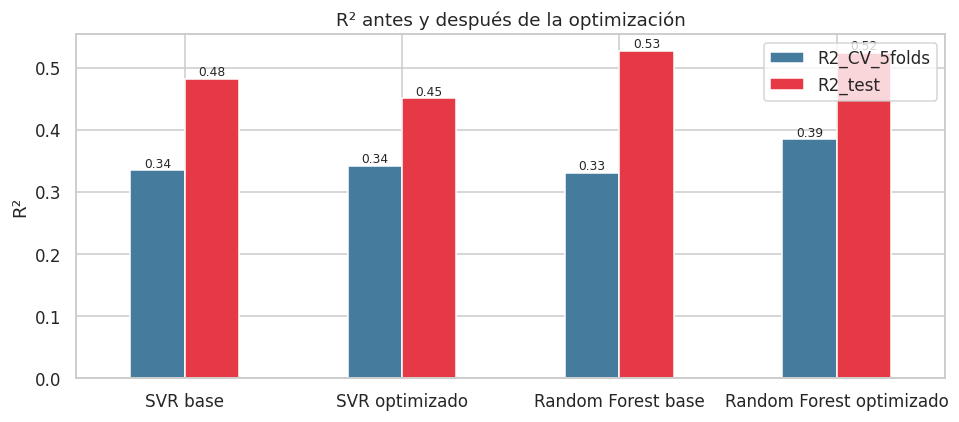

In [64]:
tabla = pd.DataFrame([
    {**res_base,    "R2_CV_5folds": cv_base.mean(),      "R2_CV_std": cv_base.std()},
    {**res_svr,     "R2_CV_5folds": gs_svr.best_score_,
     "R2_CV_std": resultados_grid.loc[gs_svr.best_index_, "std_test_score"]},
    {**res_rf_base, "R2_CV_5folds": cv_rf_base.mean(),   "R2_CV_std": cv_rf_base.std()},
    {**res_rf,      "R2_CV_5folds": gs_rf.best_score_,
     "R2_CV_std": pd.DataFrame(gs_rf.cv_results_).loc[gs_rf.best_index_, "std_test_score"]},
]).set_index("modelo")[["R2_CV_5folds", "R2_CV_std", "R2_test", "MAE_test (M/m²)", "RMSE_test (M/m²)"]]
display(tabla.round(3))

mejora_svr = gs_svr.best_score_ - cv_base.mean()
mejora_rf = gs_rf.best_score_ - cv_rf_base.mean()
print(f"📈 SVR: R² CV pasó de {cv_base.mean():.3f} a {gs_svr.best_score_:.3f} "
      f"(+{mejora_svr:.3f} puntos, {mejora_svr / abs(cv_base.mean()) * 100:+.1f}%)")
print(f"📈 RF : R² CV pasó de {cv_rf_base.mean():.3f} a {gs_rf.best_score_:.3f} "
      f"(+{mejora_rf:.3f} puntos, {mejora_rf / abs(cv_rf_base.mean()) * 100:+.1f}%)")

ax = tabla[["R2_CV_5folds", "R2_test"]].plot(kind="bar", figsize=(9, 4), color=["#457b9d", "#e63946"], rot=0)
ax.set(title="R² antes y después de la optimización", ylabel="R²", xlabel="")
for c in ax.containers:
    ax.bar_label(c, fmt="%.2f", fontsize=8)
plt.tight_layout(); plt.show()

🏆 Modelo final: Random Forest optimizado | R² train: 0.754 | R² test: 0.524


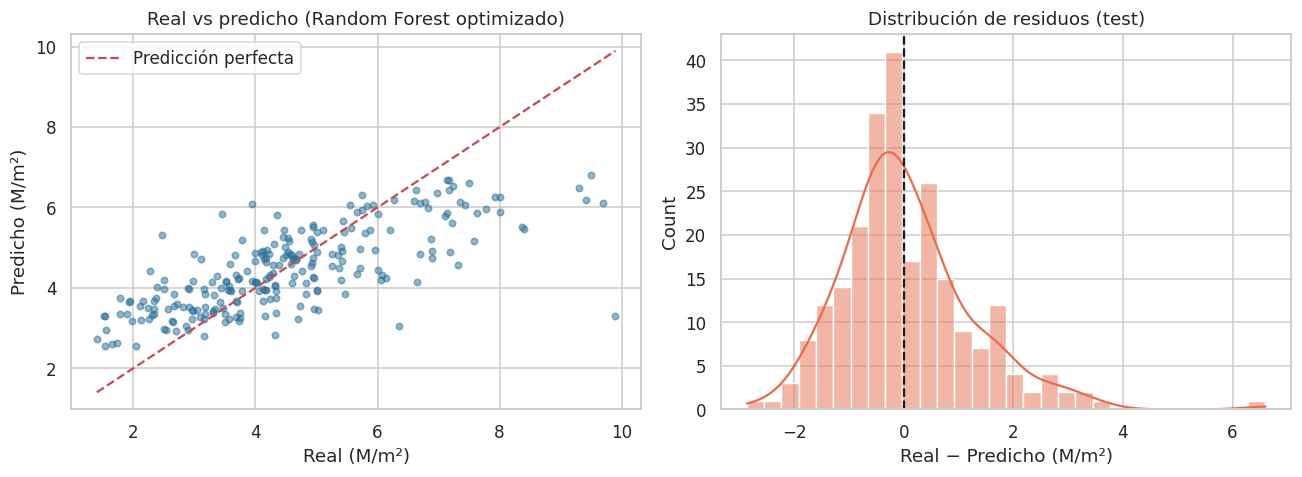

In [65]:
# ============================================================
# 4.7 Selección del modelo final y diagnóstico
# ============================================================
# Se elige por R² de validación cruzada (no por test, para no sesgar la elección)
if gs_svr.best_score_ >= gs_rf.best_score_:
    modelo_final, nombre_final = gs_svr.best_estimator_, "SVR optimizado"
else:
    modelo_final, nombre_final = gs_rf.best_estimator_, "Random Forest optimizado"
pred_test = modelo_final.predict(X_test)

# Sobreajuste: comparar train vs test
r2_train = r2_score(y_train, modelo_final.predict(X_train))
print(f"🏆 Modelo final: {nombre_final} | R² train: {r2_train:.3f} | R² test: {r2_score(y_test, pred_test):.3f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].scatter(y_test, pred_test, alpha=0.5, s=18, color="#2a6f97")
lim = [min(y_test.min(), pred_test.min()), max(y_test.max(), pred_test.max())]
ax[0].plot(lim, lim, "r--", label="Predicción perfecta")
ax[0].set(title=f"Real vs predicho ({nombre_final})", xlabel="Real (M/m²)", ylabel="Predicho (M/m²)")
ax[0].legend()
residuos = y_test - pred_test
sns.histplot(residuos, bins=30, kde=True, ax=ax[1], color="#e76f51")
ax[1].axvline(0, color="k", ls="--")
ax[1].set(title="Distribución de residuos (test)", xlabel="Real − Predicho (M/m²)")
plt.tight_layout(); plt.show()

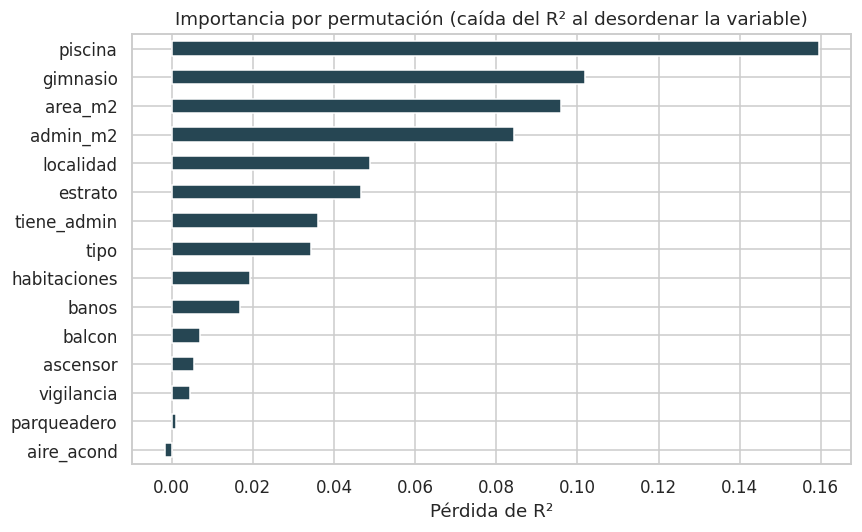

📝 Variables que más explican el precio/m²: ['piscina', 'gimnasio', 'area_m2', 'admin_m2']


In [66]:
# 4.8 Importancia de variables por permutación (sobre el test)
imp = permutation_importance(modelo_final, X_test, y_test, n_repeats=5, random_state=SEMILLA, scoring="r2", n_jobs=-1)
importancias = pd.Series(imp.importances_mean, index=X_test.columns).sort_values()
importancias.plot(kind="barh", figsize=(8, 5), color="#264653")
plt.title("Importancia por permutación (caída del R² al desordenar la variable)")
plt.xlabel("Pérdida de R²"); plt.tight_layout(); plt.show()
print("📝 Variables que más explican el precio/m²:", list(importancias.sort_values(ascending=False).head(4).index))

In [67]:
# 4.9 Uso práctico: estimar el precio de un inmueble nuevo
nuevo = pd.DataFrame([{
    "area_m2": 85, "habitaciones": 3, "banos": 2, "estrato": 5, "admin_m2": 4500,
    "tipo": "Apartamento", "localidad": "Riomar",
    "piscina": 1, "ascensor": 1, "gimnasio": 1, "parqueadero": 1, "vigilancia": 1,
    "balcon": 1, "aire_acond": 0, "tiene_admin": 1,
}])
m2_pred = modelo_final.predict(nuevo[X.columns])[0]
print(f"🏠 Apartamento de 85 m² en Riomar, estrato 5, con piscina/ascensor/gimnasio:")
print(f"   Precio estimado: {m2_pred:.2f} M/m²  →  total ≈ ${m2_pred * 85 * 1e6:,.0f} COP")

🏠 Apartamento de 85 m² en Riomar, estrato 5, con piscina/ascensor/gimnasio:
   Precio estimado: 6.11 M/m²  →  total ≈ $519,209,978 COP


## ✅ Fase V · Conclusiones
La siguiente celda resume automáticamente los hallazgos con los datos extraídos en esta ejecución.

In [68]:
print("=" * 70)
print("RESUMEN DEL PROYECTO")
print("=" * 70)
print(f"• Anuncios extraídos: {len(df_crudo)} crudos → {len(df_limpio)} limpios "
      f"({len(fragmentos)} páginas de Fincaraíz, fecha {df_crudo['fecha_extraccion'].iloc[0]})")
print(f"• Precio mediano: {df_limpio['precio_m2'].median():.2f} M COP/m²")
print(f"• Localidad más costosa: {resumen_loc.index[0]} ({resumen_loc['mediana'].iloc[0]:.2f} M/m²); "
      f"más económica: {resumen_loc.index[-1]} ({resumen_loc['mediana'].iloc[-1]:.2f} M/m²)")
print(f"• GridSearchCV mejoró el R² (CV 5 folds) del SVR de {cv_base.mean():.3f} a {gs_svr.best_score_:.3f}")
print(f"• Modelo final: {nombre_final} | R² test {r2_score(y_test, pred_test):.3f} "
      f"| error medio ±{mean_absolute_error(y_test, pred_test):.2f} M/m²")
print(f"• Variables más influyentes: {', '.join(importancias.sort_values(ascending=False).head(3).index)}")

RESUMEN DEL PROYECTO
• Anuncios extraídos: 1241 crudos → 1183 limpios (60 páginas de Fincaraíz, fecha 2026-11-20)
• Precio mediano: 4.17 M COP/m²
• Localidad más costosa: Riomar (4.83 M/m²); más económica: Metropolitana (2.23 M/m²)
• GridSearchCV mejoró el R² (CV 5 folds) del SVR de 0.335 a 0.342
• Modelo final: Random Forest optimizado | R² test 0.524 | error medio ±0.89 M/m²
• Variables más influyentes: piscina, gimnasio, area_m2


**Lectura de negocio**
- La **ubicación** (localidad/estrato) es el factor dominante del valor del m² en Barranquilla; las comodidades de conjunto (piscina, gimnasio, ascensor) agregan una prima adicional.
- El modelo sirve como **referencia objetiva** para detectar anuncios sobrevalorados o subvalorados frente a inmuebles comparables.

**Limitaciones y mejoras futuras**
- Los precios son de **oferta** (lo publicado), no de cierre de venta.
- El estrato y las comodidades se extraen del texto libre del anuncio: si el anunciante no los menciona, quedan como ausentes.
- Mejoras: agregar coordenadas geográficas (distancia al mar/centros comerciales), antigüedad del inmueble y repetir el scraping periódicamente para analizar tendencias.